# PlonkNet-10: Data Preparation
### Evan André Santana Pacheco A01769493
### TC3009C.601

Country-level geolocation of Street View images with a pretrained CNN

GeoLocation – Geoguessr Images (50K) (Kaggle)
https://www.kaggle.com/datasets/ubitquitin/geolocation-geoguessr-images-50k

License
Not specified by the author (listed as "Unknown" on Kaggle)

This notebook turns the raw Kaggle ZIP into a clean dataset ready for training. It checks the integrity of the 49,997 images (file types, color mode, exact duplicates and resolutions), explores the class distribution and selects 10 countries in two groups, easy and hard to distinguish according to the Plonk It guide. It then caps every country at 2,000 images, removes near-duplicates with a perceptual hash, splits the data into train, validation and test, and exports the images resized to 256 px of height.

**Input → Output**
`archive.zip` (raw Kaggle dataset) → `metadata.csv`, `selection_cap2000.csv`, `splits.csv`, `classes.json`, `plonknet10_256.zip` and the figures in `figures/`

**References**
- Plonk It, GeoGuessr guide: https://www.plonkit.net/guide
- GeeksforGeeks, *Finding duplicate files with Python*: https://www.geeksforgeeks.org/python/finding-duplicate-files-with-python/

###**What are we doing and producing?**

**Mini ETL:**

We are generating a metadata.csv file to track each processing step and verification performed on the raw data ZIP file. This prevents unnecessary re-execution when re-running the notebook.

**Mini EDA:**

The key output is a selection_cap2000.csv file. We use a fixed seed to sample images deterministically from countries with more than 2,000 images, reducing class imbalance.

**Visual Grids:**

The figures/p2_grid_*.jpg provides a visual inspection sample, allowing us to formulate initial hypotheses regarding expected model evaluation performance.

**Data Split:**

The splits.csv file defines the train, validation, and test partitions, categorized by country difficulty group (easy vs. hard). We also generate classes.json, which defines a fixed ordering mapping model class indices to country names. This file is required by the inference notebook for consistent mapping.

**Final Dataset Export:**

The final export, plonknet10_256.zip, contains the cleaned and resized dataset structured into train, validation, and test subfolders per country, formatted for standard PyTorch ImageFolder loading.
The training notebook only needs `plonknet10_256.zip` and `classes.json`.

## Setup: Imports, Paths and Project Settings

In [ ]:
import os
import json
import shutil
import hashlib
from collections import Counter, defaultdict

import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from google.colab import drive

# imagehash (perceptual hash)
!pip install -q imagehash
import imagehash

# ------- Paths -------
DRIVE_ROOT = '/content/drive/MyDrive/IAconcentrada/GEOGUSSR'
ZIP_DRIVE = f'{DRIVE_ROOT}/Dataset1/archive.zip'
OUT_DIR = f'{DRIVE_ROOT}/Outputs'
FIG_DIR = f'{OUT_DIR}/figures'
METADATA_CSV = f'{OUT_DIR}/metadata.csv'
SELECTION_CSV = f'{OUT_DIR}/selection_cap2000.csv'
SPLITS_CSV = f'{OUT_DIR}/splits.csv'
CLASSES_JSON = f'{OUT_DIR}/classes.json'
EXPORT_DIR = '/content/plonknet10_256'          # local disk (fast)
EXPORT_ZIP_DRIVE = f'{OUT_DIR}/plonknet10_256.zip'

# --- Project settings ---
COUNTRIES = ['United States', 'Japan', 'Brazil', 'South Africa', 'Thailand',
             'France', 'Spain', 'Poland', 'Italy', 'Germany']
EASY = ['United States', 'Japan', 'Brazil', 'South Africa', 'Thailand']
CAP = 2000
SEED = 42
TARGET_H = 256    # height of the exported images (width keeps the aspect ratio)

pd.set_option('display.max_rows', None)

## Mount Drive and extract the ZIP into Colab

If this cell says that `/content/drive` contains local files: go to **Runtime → Disconnect and delete runtime** and run the notebook again from the top. It happens when something was written to `/content/drive` while Drive was not mounted (for example, after Colab disconnected).

In [ ]:
if os.path.ismount('/content/drive'):
    print('Drive already mounted.')
elif os.path.isdir('/content/drive') and os.listdir('/content/drive'):
    raise RuntimeError('/content/drive contains local files: use Runtime > Disconnect and delete runtime.')
else:
    drive.mount('/content/drive')


os.makedirs(FIG_DIR, exist_ok=True)

# Copy the ZIP to Colab's local disk (much faster than reading images from Drive)
# and extract it only once per session; -o overwrites without asking
if not os.path.exists('/content/data/compressed_dataset'):
    !cp "{ZIP_DRIVE}" /content/archive.zip
    !unzip -q -o /content/archive.zip -d /content/data
else:
    print('Dataset already extracted in this session, skipping.')

base_path = '/content/data/compressed_dataset'
if not os.path.exists(base_path):
    # In case the ZIP structure does not include the compressed_dataset subfolder
    base_path = '/content/data'

print(sum(len(f) for _, _, f in os.walk(base_path)), 'files')

Mounted at /content/drive
49997 files


## Quick mini ETL

### Data integrity check

We check that every file is a `.jpg`; if not, we print the failing files.

In [ ]:
def check_non_images(directory):
    valid_extensions = {'.jpg'}
    non_image_files = []

    for root, _, files in os.walk(directory):
        for file in files:
            # Skip hidden files
            if file.startswith('.'):
                continue
            _, ext = os.path.splitext(file.lower())
            if ext not in valid_extensions:
                full_path = os.path.join(root, file)
                non_image_files.append(full_path)

    if non_image_files:
        print(f"Found {len(non_image_files)} files that are not images:")
        for filepath in non_image_files[:10]:
            print(f" - {filepath}")
        if len(non_image_files) > 10:
            print(" ... and more")
        raise ValueError(f"Failed: there are {len(non_image_files)} non-image file(s) in the dataset.")
    else:
        print("All good: every file found is a valid image.")

check_non_images('/content/data')

All good: every file found is a valid image.


We extract the data by walking through the folders and check that there are no repeated or non-existent countries.

In [ ]:
records = []

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith('.jpg'):
            country = os.path.basename(root)
            full_path = os.path.join(root, file)
            records.append({'country': country, 'path': full_path})

df = pd.DataFrame(records)

# Show the results in alphabetical order
print("Number of images per country/folder:")
print(df['country'].value_counts().sort_index())

Number of images per country/folder:
country
Aland                                           9
Albania                                        41
American Samoa                                 16
Andorra                                        13
Antarctica                                      1
Argentina                                     689
Armenia                                         1
Australia                                    1704
Austria                                       347
Bangladesh                                    106
Belarus                                         1
Belgium                                       219
Bermuda                                         3
Bhutan                                         20
Bolivia                                       116
Botswana                                      144
Brazil                                       2320
Bulgaria                                      217
Cambodia                                      118
Canad

Some folders are regions or territories that belong to other countries, and some are islands that are not recognized as independent countries. We will decide how to handle this data later, in the mini EDA.

We used this function to double-check the folders whose region was unclear.

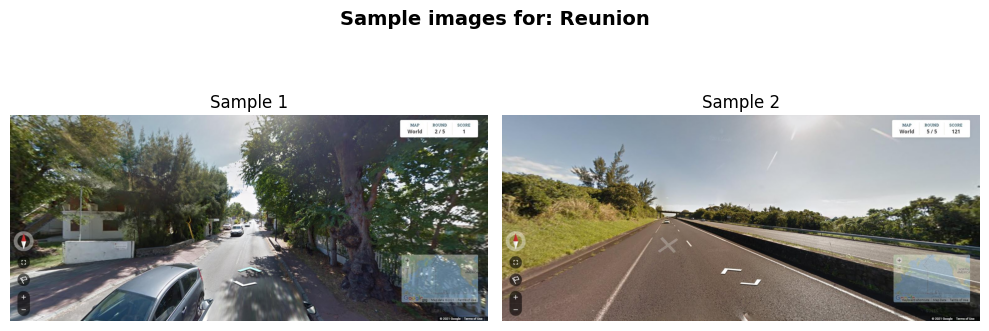

In [ ]:
countries_to_check = ['Reunion']
images_per_country = 2

def show_country_samples(country_list, n_images=2):
    for target_country in country_list:
        sub_df = df[df['country'].str.lower() == target_country.lower()]

        if sub_df.empty:
            print(f"\nNo images found for country: '{target_country}'. The name does not match or does not exist.")
            continue

        samples = sub_df.head(n_images)
        n_samples = len(samples)
        fig, axes = plt.subplots(1, n_samples, figsize=(5 * n_samples, 4))
        fig.suptitle(f"Sample images for: {target_country}", fontsize=14, fontweight='bold')

        if n_samples == 1:
            axes = [axes]

        for idx, (_, row) in enumerate(samples.iterrows()):
            try:
                img = Image.open(row['path'])
                axes[idx].imshow(img)
                axes[idx].set_title(f"Sample {idx+1}")
                axes[idx].axis('off')
            except Exception as e:
                axes[idx].text(0.5, 0.5, f"Error opening image\n{e}", ha='center', va='center')
                axes[idx].axis('off')

        plt.tight_layout()
        plt.show()

show_country_samples(countries_to_check, n_images=images_per_country)

We validate that every photo is in color (RGB mode) and count the ones that are not.

In [ ]:
def check_rgb_channels(dataframe):
    non_rgb = []
    total_images = len(dataframe)

    print(f"Checking {total_images} images.")

    for idx, row in dataframe.iterrows():
        path = row['path']
        try:
            with Image.open(path) as img:
                if img.mode != 'RGB':
                    non_rgb.append((path, img.mode))
        except Exception as e:
            non_rgb.append((path, f"Error opening: {str(e)}"))

    if not non_rgb:
        print("\nPerfect: every image is valid and in RGB mode.")
    else:
        print(f"\nFound {len(non_rgb)} images that are NOT RGB:")
        for bad_path, mode in non_rgb[:10]:
            print(f" - {bad_path} (Mode: {mode})")
        if len(non_rgb) > 10:
            print(" ... and more")

check_rgb_channels(df)

Checking 49997 images.

Perfect: every image is valid and in RGB mode.


We check how many image formats exist by looking at their resolution in pixels and their dimensions (width × height). We take the first image as a reference, compare the rest against it and store every unique format found. Then we print the formats.

In [ ]:
def check_resolutions(dataframe):
    if dataframe.empty:
        print("The DataFrame is empty.")
        return

    print(f"Processing {len(dataframe)} images...")

    first_path = dataframe.iloc[0]['path']
    try:
        with Image.open(first_path) as img:
            ref_width, ref_height = img.size
            ref_ratio = ref_width / ref_height
    except Exception as e:
        print(f"Error opening the reference image {first_path}: {e}")
        return

    unique_formats = {((ref_width, ref_height), round(ref_ratio, 4))}

    for idx, row in dataframe.iloc[1:].iterrows():
        path = row['path']
        try:
            with Image.open(path) as img:
                width, height = img.size
                if (width, height) != (ref_width, ref_height):
                    ratio = width / height
                    unique_formats.add(((width, height), round(ratio, 4)))
        except Exception as e:
            print(f"Could not read image {path}: {e}")


    if len(unique_formats) == 1:
        print(f"\nSingle value: every image has the same format")
        print(f"Single resolution: {ref_width}x{ref_height} pixels (Aspect ratio: {round(ref_ratio, 4)})")
    else:
        print(f"\nFound {len(unique_formats)} different formats in the dataset:")
        for (res, ratio) in sorted(unique_formats):
            print(f" - Resolution: {res[0]}x{res[1]} pixels | Aspect ratio (width/height): {ratio}")

check_resolutions(df)

Processing 49997 images...

Found 2 different formats in the dataset:
 - Resolution: 1030x703 pixels | Aspect ratio (width/height): 1.4651
 - Resolution: 1536x662 pixels | Aspect ratio (width/height): 2.3202


Since there are two formats, we analyze what percentage of the images belongs to each one; the smaller group is the one we will look into, since it is easier to handle.

In [ ]:
def count_image_formats(dataframe):
    if dataframe.empty:
        print("The DataFrame is empty.")
        return

    print(f"Counting formats for {len(dataframe)} images...")
    counts = Counter()

    for idx, row in dataframe.iterrows():
        path = row['path']
        try:
            with Image.open(path) as img:
                width, height = img.size
                ratio = round(width / height, 4)
                counts[(width, height, ratio)] += 1
        except Exception as e:
            counts[('Error', 'Error', 'Error')] += 1

    print("\nCount results:")
    for (width, height, ratio), amount in counts.items():
        if width == 'Error':
            print(f" - Corrupt or unreadable files: {amount}")
        else:
            print(f" - Resolution: {width}x{height} | Aspect ratio: {ratio} | Total: {amount} images ({amount/len(dataframe)*100:.2f}%)")

count_image_formats(df)

Counting formats for 49997 images...

Count results:
 - Resolution: 1536x662 | Aspect ratio: 2.3202 | Total: 49942 images (99.89%)
 - Resolution: 1030x703 | Aspect ratio: 1.4651 | Total: 55 images (0.11%)


We check whether there are images with duplicated content, regardless of their file name, by computing their MD5 hash. We print the stats: files processed, groups of identical images, total files that have a duplicate and number of redundant images.

In [ ]:
def compute_md5(file_path):
    # Computes the MD5 hash of a file, reading it in blocks to avoid filling the memory
    md5_hash = hashlib.md5()
    try:
        with open(file_path, "rb") as f:
            for block in iter(lambda: f.read(4096), b""):
                md5_hash.update(block)
        return md5_hash.hexdigest()
    except Exception as e:
        return f"Error: {e}"

def find_exact_duplicates(dataframe):
    if dataframe.empty:
        print("The DataFrame is empty.")
        return

    print(f"Computing MD5 for {len(dataframe)} images...")

    hashes = defaultdict(list)

    for idx, row in dataframe.iterrows():
        path = row['path']
        md5_value = compute_md5(path)
        if not md5_value.startswith("Error"):
            hashes[md5_value].append(path)
        if (idx + 1) % 10000 == 0:
            print(f" Processed {idx + 1} of {len(dataframe)} images...")


    duplicates = {hash_val: paths for hash_val, paths in hashes.items() if len(paths) > 1}


    total_duplicate_groups = len(duplicates)
    total_duplicate_files = sum(len(paths) for paths in duplicates.values())

    redundant_files = total_duplicate_files - total_duplicate_groups

    print("\n=== DUPLICATE ANALYSIS RESULTS ===")
    print(f"- Total files processed: {len(dataframe)}")
    print(f"- Groups of identical images found: {total_duplicate_groups}")
    print(f"- Total files that have a duplicate: {total_duplicate_files}")
    print(f"- Number of extra (redundant) images: {redundant_files}")

    if total_duplicate_groups > 0:
        print("\nExamples of duplicate files found (first 5 groups):")
        for i, (hash_val, paths) in enumerate(list(duplicates.items())[:5]):
            print(f"\nGroup {i+1} (MD5 hash: {hash_val}):")
            print(f"  Appears {len(paths)} times:")
            for p in paths[:3]:
                print(f"   - {p}")
            if len(paths) > 3:
                print("   - ... and more")
    else:
        print("\nExcellent! No identical images were found by MD5 hash.")


find_exact_duplicates(df)

Computing MD5 for 49997 images...
 Processed 10000 of 49997 images...
 Processed 20000 of 49997 images...
 Processed 30000 of 49997 images...
 Processed 40000 of 49997 images...

=== DUPLICATE ANALYSIS RESULTS ===
- Total files processed: 49997
- Groups of identical images found: 1
- Total files that have a duplicate: 2
- Number of extra (redundant) images: 1

Examples of duplicate files found (first 5 groups):

Group 1 (MD5 hash: 3a54d81dee2545de641d557ca103f54c):
  Appears 2 times:
   - /content/data/compressed_dataset/Ghana/canvas_1629501800.jpg
   - /content/data/compressed_dataset/Ghana/canvas_1629388332.jpg


Since there is only one duplicate, we display both images to verify them.

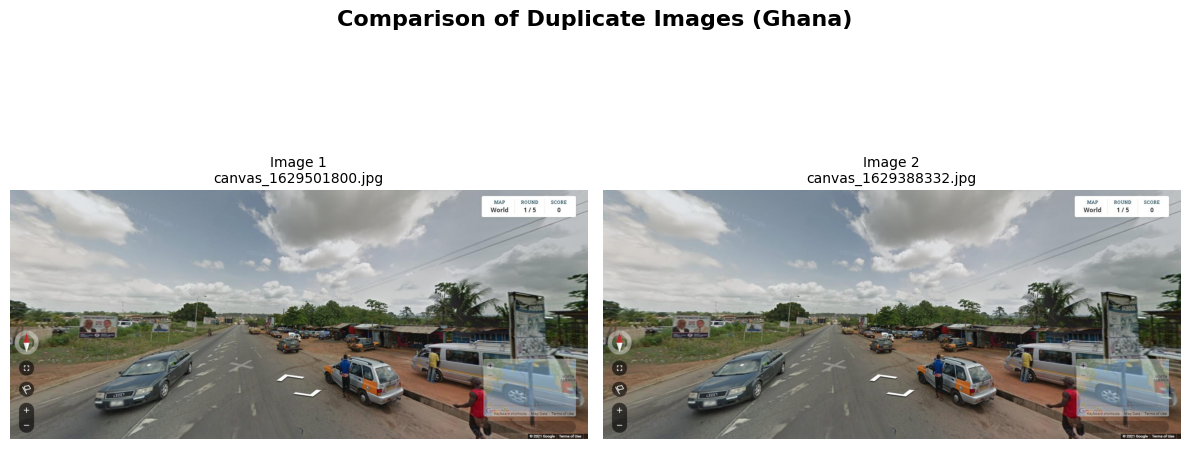

In [ ]:
duplicate_paths = [
    "/content/data/compressed_dataset/Ghana/canvas_1629501800.jpg",
    "/content/data/compressed_dataset/Ghana/canvas_1629388332.jpg"
]

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
fig.suptitle("Comparison of Duplicate Images (Ghana)", fontsize=16, fontweight='bold')

for idx, path in enumerate(duplicate_paths):
    try:
        img = Image.open(path)
        axes[idx].imshow(img)
        axes[idx].set_title(f"Image {idx+1}\n{path.split('/')[-1]}", fontsize=10)
        axes[idx].axis('off')
    except Exception as e:
        axes[idx].text(0.5, 0.5, f"Error opening image:\n{e}", ha='center', va='center')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

### Export the metadata to a CSV

One row per image. Files are **not deleted** from disk: the redundant copy of each duplicate is flagged (`is_duplicate = True`, `valid = False`) so it stays documented and is excluded later. Paths are stored relative to `base_path`, so the CSV keeps working every time the ZIP is extracted again.

In [ ]:

output_csv_path = METADATA_CSV
records = []

print("Validating images, computing MD5 hashes and extracting metadata...")
for root, _, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            full_path = os.path.join(root, file)

            file_format = None
            mode = None
            width = None
            height = None
            valid = True

            try:
                with Image.open(full_path) as img:
                    img.verify()  # First check

                with Image.open(full_path) as img:
                    file_format = img.format  # Real format, not just the extension
                    mode = img.mode
                    width, height = img.size
            except Exception as e:
                valid = False

            records.append({
                'path': os.path.relpath(full_path, base_path),
                'country': os.path.basename(root),
                'source': 'geoguessr50k',
                'format': file_format,
                'mode': mode,
                'width': width,
                'height': height,
                'bytes': os.path.getsize(full_path),
                'md5': compute_md5(full_path),
                'valid': valid
            })

df_report = pd.DataFrame(records).sort_values('path').reset_index(drop=True)

# Flag duplicates: keep the first copy, mark the rest as redundant
df_report['is_duplicate'] = df_report.duplicated(subset='md5', keep='first')
df_report.loc[df_report['is_duplicate'], 'valid'] = False

# A duplicate across two different countries would be a labeling error
dup_groups = df_report[df_report.duplicated(subset='md5', keep=False)]
cross_country = dup_groups.groupby('md5')['country'].nunique()
print(f"Duplicate groups with different countries (labeling errors): {(cross_country > 1).sum()}")

df_report.to_csv(output_csv_path, index=False, encoding='utf-8')

print(f"\nReport successfully exported to your Google Drive: {output_csv_path}")
print(f"Total images recorded in the report: {len(df_report)}")
print(f"Valid images: {df_report['valid'].sum()} | Invalid: {(~df_report['valid']).sum()}")
print(f"Images flagged as duplicates: {df_report['is_duplicate'].sum()}")

Validating images, computing MD5 hashes and extracting metadata...
Duplicate groups with different countries (labeling errors): 0

Report successfully exported to your Google Drive: /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/metadata.csv
Total images recorded in the report: 49997
Valid images: 49996 | Invalid: 1
Images flagged as duplicates: 1


### Resolution by country

If the minority resolution is concentrated in a few countries, the model could learn "this image shape = this country" instead of the scenery (a shortcut). If it is spread out, it is just noted as a characteristic of the data.

In [ ]:
df_report['resolution'] = df_report['width'].astype(str) + 'x' + df_report['height'].astype(str)
res_counts = df_report['resolution'].value_counts()
print(res_counts)

minority_res = res_counts.idxmin()
minority = df_report[df_report['resolution'] == minority_res]

summary = pd.DataFrame({
    'images_minority_res': minority['country'].value_counts(),
    'total_images': df_report['country'].value_counts()
}).dropna().astype(int)
summary['pct_of_country'] = (summary['images_minority_res'] / summary['total_images'] * 100).round(2)

print(f"\nCountries with images at {minority_res}:")
print(summary.sort_values('images_minority_res', ascending=False))

resolution
1536x662    49942
1030x703       55
Name: count, dtype: int64

Countries with images at 1030x703:
                images_minority_res  total_images  pct_of_country
country                                                          
United States                     8         12014            0.07
Japan                             6          3840            0.16
France                            4          3573            0.11
Brazil                            4          2320            0.17
Sweden                            3           726            0.41
Canada                            3          1382            0.22
Germany                           2           698            0.29
Australia                         2          1704            0.12
Russia                            2          1761            0.11
Norway                            2           675            0.30
South Africa                      2          1183            0.17
Argentina                        

**Conclusion:** the 55 images at 1030×703 are spread across 28 countries, and in the 10 selected countries they are at most 0.29% of a country (Germany, 2 of 698). The image size cannot work as a shortcut for the model, so it is only noted as a characteristic of the data.

## Mini EDA

Shortcut used only to re run the mini-EDA part without rerunning the whole notebook; this cell loads the saved metadata so the EDA can then run normally.

In [ ]:
if 'df_report' not in globals():
    df_report = pd.read_csv(METADATA_CSV)
    print('Loaded metadata.csv from Drive')
if 'df' not in globals():
    df = df_report.copy()

print(len(df_report), 'images in the metadata')

49997 images in the metadata


Before EDA, I manually looked into and investigated countries, reaching conclusions through notes on whether some countries could match, or if they were geographically near or politically connected. However, the ultimate decisions will be based on the EDA results.

We get the distribution of the countries' mean and median to get more of an idea of what we are working with.

--- Photo Statistics per Country ---
Mean number of photos per country: 403.20
Median number of photos per country: 81.00
Total countries: 124
Total images: 49997
-------------------------------------


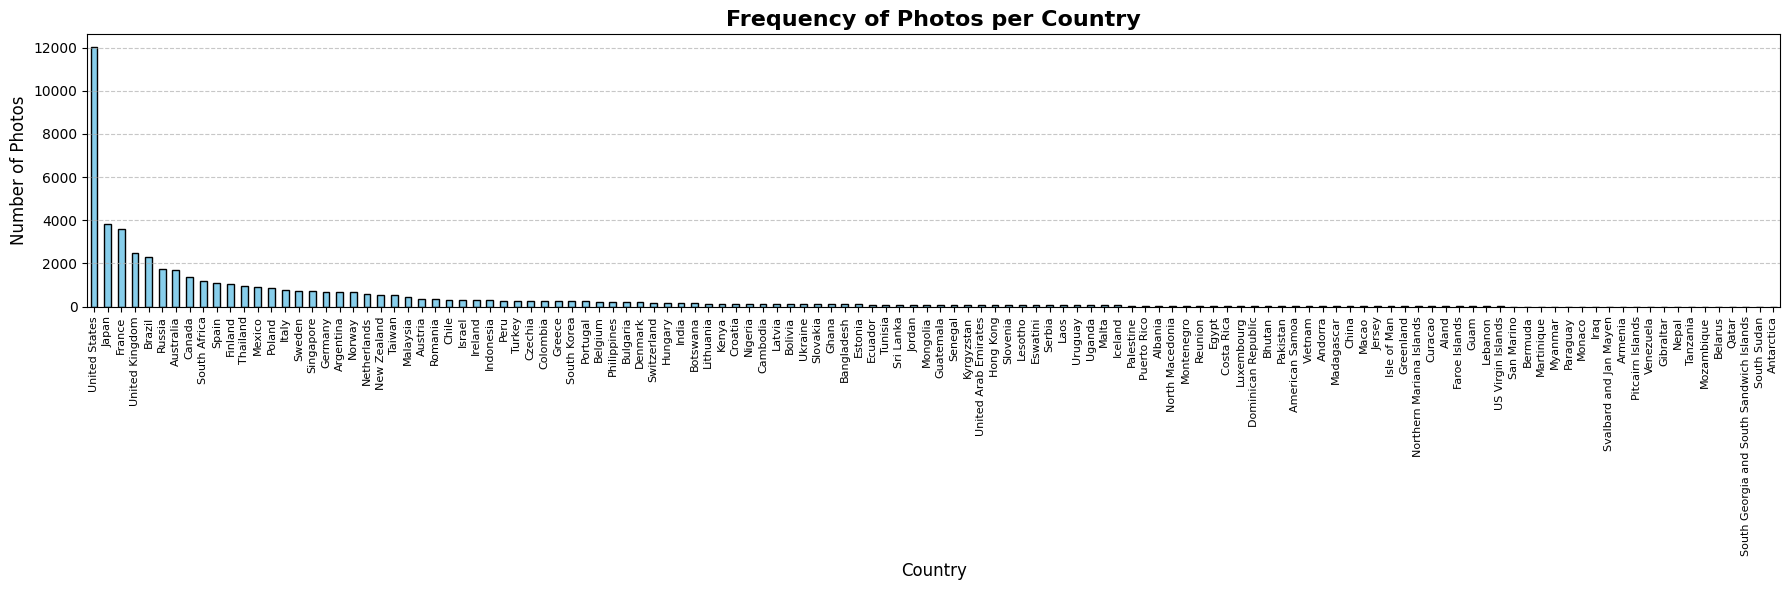

In [ ]:
country_counts = df['country'].value_counts()

mean_photos = country_counts.mean()
median_photos = country_counts.median()

print(f"--- Photo Statistics per Country ---")
print(f"Mean number of photos per country: {mean_photos:.2f}")
print(f"Median number of photos per country: {median_photos:.2f}")
print(f"Total countries: {len(country_counts)}")
print(f"Total images: {country_counts.sum()}")
print("-------------------------------------")

plt.figure(figsize=(18, 6))
country_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Frequency of Photos per Country", fontsize=16, fontweight='bold')
plt.xlabel("Country", fontsize=12)
plt.ylabel("Number of Photos", fontsize=12)
plt.xticks(rotation=90, fontsize=8)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

We are interested in countries that have many photos.

In [ ]:
above_mean = country_counts[country_counts > mean_photos].count()
above_median = country_counts[country_counts > median_photos].count()

print(f"--- Country Counts Relative to Average Statistics ---")
print(f"Number of countries above the mean ({mean_photos:.2f} photos): {above_mean}")
print(f"Number of countries above the median ({median_photos:.1f} photos): {above_median}")
print(f"------------------------------------------------------")

--- Country Counts Relative to Average Statistics ---
Number of countries above the mean (403.20 photos): 24
Number of countries above the median (81.0 photos): 62
------------------------------------------------------


We will select the 24 countries with the highest number of photos. From this subset, we will choose 10 countries in total, 5 that are easy to distinguish and 5 that are difficult to differentiate based on the guide plonk it.

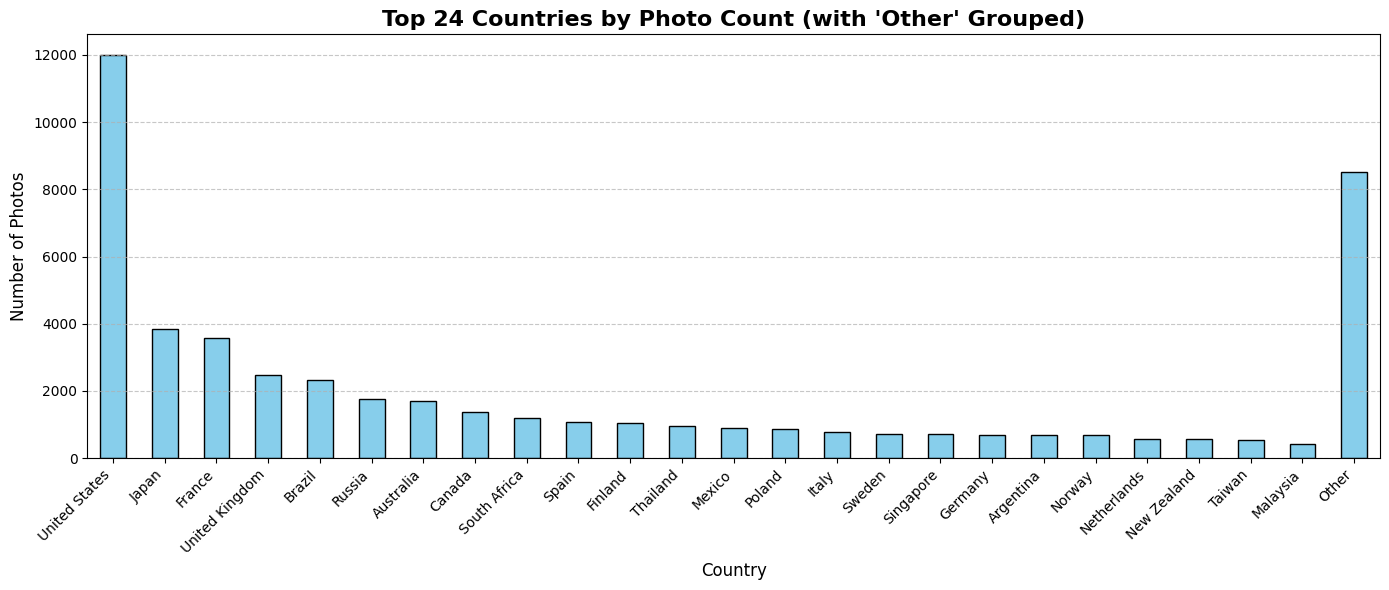

In [ ]:
top_24 = country_counts.head(24)
other_sum = country_counts.iloc[24:].sum()
top_countries_with_other = pd.concat([top_24, pd.Series({'Other': other_sum})])

plt.figure(figsize=(14, 6))
top_countries_with_other.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Top 24 Countries by Photo Count (with 'Other' Grouped)", fontsize=16, fontweight='bold')
plt.xlabel("Country", fontsize=12)
plt.ylabel("Number of Photos", fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

In [ ]:
top_24_countries = country_counts.head(24)

print("--- Top 24 Countries by Photo Count ---")
for rank, (country, count) in enumerate(top_24_countries.items(), 1):
    print(f"{rank:2d}. {country:<20} : {count:,} photos")
print("----------------------------------------")

--- Top 24 Countries by Photo Count ---
 1. United States        : 12,014 photos
 2. Japan                : 3,840 photos
 3. France               : 3,573 photos
 4. United Kingdom       : 2,484 photos
 5. Brazil               : 2,320 photos
 6. Russia               : 1,761 photos
 7. Australia            : 1,704 photos
 8. Canada               : 1,382 photos
 9. South Africa         : 1,183 photos
10. Spain                : 1,075 photos
11. Finland              : 1,049 photos
12. Thailand             : 944 photos
13. Mexico               : 901 photos
14. Poland               : 863 photos
15. Italy                : 789 photos
16. Sweden               : 726 photos
17. Singapore            : 707 photos
18. Germany              : 698 photos
19. Argentina            : 689 photos
20. Norway               : 675 photos
21. Netherlands          : 579 photos
22. New Zealand          : 557 photos
23. Taiwan               : 547 photos
24. Malaysia             : 423 photos
-------------------------

After deliberation, the selected countries are **United States, Japan, Brazil, South Africa and Thailand** (easy-to-distinguish group) and **France, Spain, Poland, Italy and Germany** (hard-to-distinguish group). The group comes from the Plonk It guide; among the candidates, we chose the countries with the most photos so every class has a good sample. The full reasoning is in the documentation.

### **Dataset Group Justification**

| Country | Photos (final) | Group | Expected Confusion |
| --- | --- | --- | --- |
| **United States** | 2,000 | Easy | Japan |
| **Japan** | 2,000 | Easy | United States |
| **Brazil** | 2,000 | Easy | Thailand |
| **South Africa** | 1,177 | Easy | — (Best distinguished) |
| **Thailand** | 941 | Easy | Brazil |
| **France** | 2,000 | Hard | Poland |
| **Spain** | 1,071 | Hard | Italy |
| **Poland** | 857 | Hard | France |
| **Italy** | 787 | Hard | — (Easiest of the hard group) |
| **Germany** | 694 | Hard | France / Poland |

---

#### **Why the "Easy" Group is Distinct (Macro Clues)**

- **United States:** Marked by bold macro features: standard double-yellow centerlines, right-hand driving, and distinct rectangular license plate layouts.
- **Japan vs. USA:** Direct structural opposites: left-hand driving, low-camera height (Gen 4), and high-density character blobs (Kanji/Kana textures) on utility poles.
- **Brazil vs. Thailand:** Distinct macro environments and script textures. Brazil features right-hand driving, red soil, and Latin text blocks; Thailand features left-hand driving, dense cable bundles, and intricate, curved Thai script textures.
- **South Africa:** Unique continental footprint: left-hand driving with continuous yellow outer shoulder lines (instead of centerlines) and high-contrast black/yellow chevron signs.

---

#### **Why the "Hard" Group is Confusing (Micro Clues & Pixelation)**

- **European Standard Uniformity:** All 5 countries belong to the EU/Schengen area and follow the Vienna Convention, sharing identical macro-scenery, road layouts, and temperate vegetation.
- **Micro-Clue Degradation at 256px:** Because these countries look nearly identical at a macro level, differentiation relies heavily on **micro-clues** (such as specific bollard reflector caps or minor license plate strips). At 256px, these fine details pixelate and wash out, making them extremely difficult for the model to parse.
- **France vs. Poland / Germany:** Identical rural pine/oak forests and flat agricultural fields, forcing reliance on subtle bollard differences (e.g., white/red in France vs. red/white *U-12a* in Poland).
- **Spain vs. Italy:** Shared Mediterranean architecture. Italy slightly stands out due to its smaller front license plate geometry with double blue side strips, while Spain relies on local kilometer markers.
- **Germany:** High rural similarity to France and Poland, distinguished primarily by legacy residential blur (Gen 3) and specific typography textures on signs.

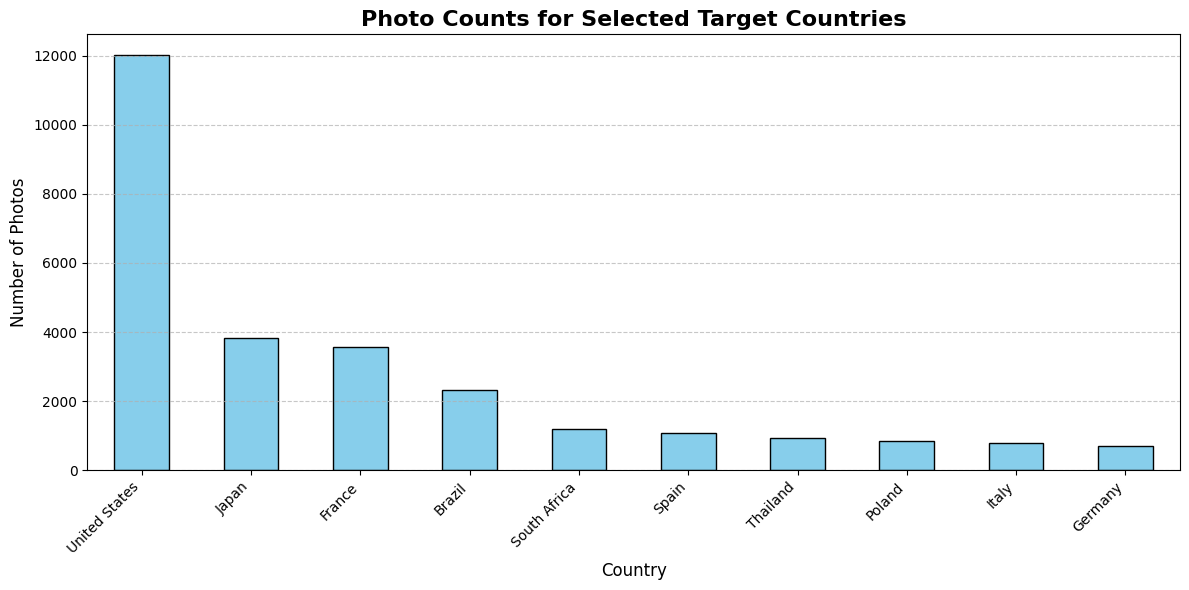

In [ ]:
selected_counts = country_counts.reindex(COUNTRIES).sort_values(ascending=False)

plt.figure(figsize=(12, 6))
selected_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Photo Counts for Selected Target Countries", fontsize=16, fontweight='bold')
plt.xlabel("Country", fontsize=12)
plt.ylabel("Number of Photos", fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

Then, we will proceed to make an adjustment: the USA, Japan, and France contain more than 3k photos, which causes an important imbalance in comparison with the other classes that we will train on our model. Especially the USA with 12k photos, so we will cap all groups to a maximum of 2k photos and, to avoid bias, we will select them at random.

In [ ]:
selected = df_report[df_report['country'].isin(COUNTRIES) & df_report['valid']]

df_cap = selected.sample(frac=1, random_state=SEED).groupby('country').head(CAP).reset_index(drop=True)

df_cap.to_csv(SELECTION_CSV, index=False)

print("--- Final Image Counts per Country in Capped Dataset ---")
print(df_cap['country'].value_counts())
print(f"\nTotal: {len(df_cap)} images")
print(f"Dataset exported successfully to: {SELECTION_CSV}")

--- Final Image Counts per Country in Capped Dataset ---
country
Japan            2000
United States    2000
France           2000
Brazil           2000
South Africa     1183
Spain            1075
Thailand          944
Poland            863
Italy             789
Germany           698
Name: count, dtype: int64

Total: 13552 images
Dataset exported successfully to: /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/selection_cap2000.csv


### Visual grid

20 random images per selected country, saved as JPG in `figures/` (for the report). Only two grids are shown here to keep the notebook light; the rest are reviewed in Drive. Each thumbnail shows its file name, so a bad image can be excluded below.

In [ ]:
def save_country_grid(country, n=20, cols=4, seed=SEED, show=False):
    sample = df_cap[df_cap['country'] == country].sample(n=n, random_state=seed)
    rows = -(-n // cols)  # ceiling division
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 1.8))
    for ax, (_, row) in zip(axes.flat, sample.iterrows()):
        with Image.open(os.path.join(base_path, row['path'])) as img:
            img.thumbnail((400, 400))  # small thumbnail, less memory
            ax.imshow(img)
        ax.set_title(os.path.basename(row['path']), fontsize=7)  # file name, to exclude it later
    for ax in axes.flat:
        ax.axis('off')
    fig.suptitle(f'{country}: {n} random samples', fontsize=13, fontweight='bold')
    plt.tight_layout()
    fig.savefig(f'{FIG_DIR}/p2_grid_{country.replace(" ", "_")}.jpg', dpi=80)
    if show:
        plt.show()
    else:
        plt.close(fig)

for c in COUNTRIES:
    save_country_grid(c, show=(c in ['United States', 'France']))

Output hidden; open in https://colab.research.google.com to view.

**Findings from the grids** *(TODO)*

- Wrong labels: TODO
- Images that are not a street (indoors, tunnels, only sky): TODO
- Game UI elements (compass, minimap, buttons) and where they appear: TODO
- Watermarks or black borders: TODO
- **Visual similarity across groups:** many United States and France samples look alike (TODO: say what looks alike, e.g. roads, vegetation, houses). Both countries are kept on purpose: measuring these confusions is part of the experiment (hypothesis 5).

In [ ]:
# Images you decided to exclude after the grids (relative paths, as in df_cap['path']). Leave empty if none.
EXCLUDE = []   # e.g. ['France/canvas_1629400000.jpg']

df_cap = df_cap[~df_cap['path'].isin(EXCLUDE)].reset_index(drop=True)
print(f'{len(EXCLUDE)} images excluded, {len(df_cap)} remain')

0 images excluded, 13552 remain


### Near-duplicates (perceptual hash)

To avoid data leakage, we will identify byte-identical files using MD5 hashes and track exact duplicates. For each image we will detect and count visually near-identical photos with a perceptual hash.

In [ ]:
phashes = []
total_images = len(df_cap)
print(f"Computing perceptual hashes for {total_images} images...")

for idx, (_, row) in enumerate(df_cap.iterrows(), 1):
    img_path = os.path.join(base_path, row['path'])
    try:
        with Image.open(img_path) as img:
            # Compute the perceptual hash and convert to a hex string
            h = imagehash.phash(img)
            phashes.append(str(h))
    except Exception as e:
        # Fallback if an image is unreadable
        phashes.append(f"Error_{idx}")

    if idx % 2000 == 0 or idx == total_images:
        print(f"  Processed {idx}/{total_images} images...")

# Store the results back to df_cap
df_cap['phash'] = phashes
df_cap['dup_group'] = df_cap['phash']

# Count the near-duplicates (images that share their hash with at least one other)
duplicated_mask = df_cap['phash'].duplicated(keep=False)
n_duplicates = duplicated_mask.sum()

print("\n=== NEAR-DUPLICATE ANALYSIS (pHash) ===")
print(f"Total images: {total_images}")
print(f"Number of images sharing visual hash (near-duplicates): {n_duplicates} ({n_duplicates / total_images * 100:.2f}%)")

if n_duplicates > 0:
    print("\nNear-duplicates detected per country:")
    print(df_cap[duplicated_mask]['country'].value_counts())
else:
    print("\nNo visual near-duplicates detected! Every image has a unique perceptual hash.")

Computing perceptual hashes for 13552 images...
  Processed 2000/13552 images...
  Processed 4000/13552 images...
  Processed 6000/13552 images...
  Processed 8000/13552 images...
  Processed 10000/13552 images...
  Processed 12000/13552 images...
  Processed 13552/13552 images...

=== NEAR-DUPLICATE ANALYSIS (pHash) ===
Total images: 13552
Number of images sharing visual hash (near-duplicates): 94 (0.69%)

Near-duplicates detected per country:
country
Brazil           26
Japan            16
South Africa     12
Poland           12
Germany           8
Spain             8
Thailand          6
Italy             4
United States     2
Name: count, dtype: int64


**Visual check of a near-duplicate pair.** Before removing anything, we display two images that share the same perceptual hash to confirm they really are the same place. Change `TARGET_COUNTRY` to inspect other countries.

Found near-duplicates! Group pHash: 8ccee53f668c8463
Showing the first 2 images sharing this hash in Brazil:



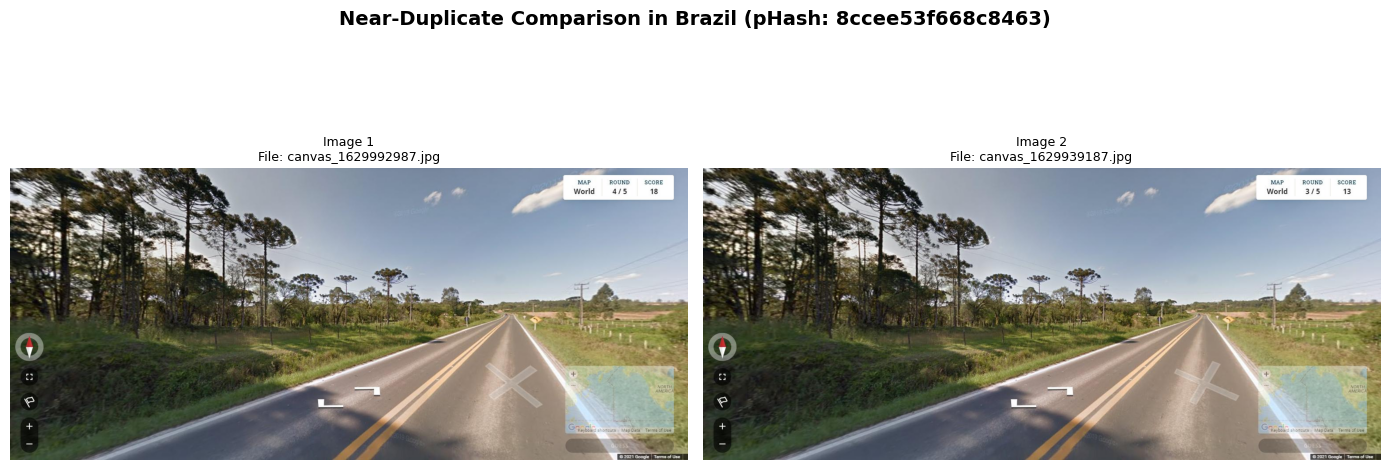

In [ ]:
# Change to check
TARGET_COUNTRY = 'Brazil'


df_country = df_cap[df_cap['country'] == TARGET_COUNTRY]
duplicated_hashes = df_country[df_country['phash'].duplicated(keep=False)]['phash'].unique()

if len(duplicated_hashes) == 0:
    print(f"No near-duplicates found in df_cap for {TARGET_COUNTRY}.")
else:

    chosen_hash = duplicated_hashes[0]
    dup_group = df_country[df_country['phash'] == chosen_hash]

    print(f"Found near-duplicates! Group pHash: {chosen_hash}")
    print(f"Showing the first 2 images sharing this hash in {TARGET_COUNTRY}:\n")

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    fig.suptitle(f"Near-Duplicate Comparison in {TARGET_COUNTRY} (pHash: {chosen_hash})", fontsize=14, fontweight='bold')

    for idx, (_, row) in enumerate(dup_group.head(2).iterrows()):
        img_path = os.path.join(base_path, row['path'])
        try:
            img = Image.open(img_path)
            axes[idx].imshow(img)
            axes[idx].set_title(f"Image {idx+1}\nFile: {os.path.basename(row['path'])}", fontsize=9)
            axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, f"Error loading image:\n{e}", ha='center', va='center')
            axes[idx].axis('off')

    plt.tight_layout()
    plt.show()

**Near-duplicate resolution.** For every group of images that share a hash, the first image is kept and the others are handled as follows:

- If the country still has unused images in the original pool (countries capped at 2,000), the duplicate is **replaced** with a random unused image whose hash is not already in the selection.
- If the country has no unused images left (countries under the cap), the duplicate is **removed**.

The loop repeats until no shared hashes remain.

**Result:** 94 images (0.69%) shared their hash in 47 pairs. 22 duplicates were replaced (Brazil, Japan, United States) and 25 were removed (South Africa, Spain, Thailand, Poland, Italy, Germany). The final selection has 13,527 images, and the four capped countries keep 2,000 each.

In [ ]:
print("=== STARTING AUTOMATIC NEAR-DUPLICATE RESOLUTION LOOP ===")

used_paths = set(df_cap['path'])
available_pool = df_report[
    df_report['valid'] &
    df_report['country'].isin(COUNTRIES) &
    (~df_report['path'].isin(used_paths))
].copy()

iteration = 0
max_iterations = 10

while True:
    iteration += 1
    duplicated_mask = df_cap['phash'].duplicated(keep='first')
    n_dups = duplicated_mask.sum()

    if n_dups == 0:
        print(f"\nSuccess No near-duplicates remain after {iteration-1} iterations.")
        break

    if iteration > max_iterations:
        print(f"\nReached maximum iteration limit ({max_iterations}). Stopping process.")
        break

    print(f"\n--- Iteration {iteration} ---")
    print(f"Found {n_dups} duplicate images to replace or remove.")

    indices_to_drop = []

    for idx, row in df_cap[duplicated_mask].iterrows():
        country = row['country']
        current_hashes = set(df_cap['phash'])

        candidates = available_pool[available_pool['country'] == country]

        success = False
        if not candidates.empty:

            shuffled_candidates = candidates.sample(frac=1, random_state=SEED + iteration)
            for c_idx, candidate_row in shuffled_candidates.iterrows():
                candidate_path = candidate_row['path']

                try:
                    with Image.open(os.path.join(base_path, candidate_path)) as img:
                        candidate_hash = str(imagehash.phash(img))

                    if candidate_hash not in current_hashes:
                        # Safe replacement finder
                        df_cap.loc[idx, ['path', 'format', 'mode', 'width', 'height', 'bytes', 'md5', 'phash', 'dup_group']] = [
                            candidate_path, candidate_row['format'], candidate_row['mode'],
                            candidate_row['width'], candidate_row['height'], candidate_row['bytes'],
                            candidate_row['md5'], candidate_hash, candidate_hash
                        ]

                        available_pool = available_pool.drop(c_idx)
                        success = True
                        break
                except Exception:
                    continue

        if not success:
            # No replacement candidates left for this country (ex Germany is fully capped)
            # We remove this duplicate to clean the dataset
            indices_to_drop.append(idx)

    if indices_to_drop:
        print(f"  No replacement candidates left for {len(indices_to_drop)} images. Removing duplicates directly.")
        df_cap = df_cap.drop(indices_to_drop).reset_index(drop=True)

# Final summary
print("\n=== RESOLUTION SUMMARY ===")
print(f"Total images left in df_cap: {len(df_cap)}")
print(df_cap['country'].value_counts())
print(f"Verified duplicate count (pHash): {df_cap['phash'].duplicated(keep=False).sum()}")

=== STARTING AUTOMATIC NEAR-DUPLICATE RESOLUTION LOOP ===

Success No near-duplicates remain after 0 iterations.

=== RESOLUTION SUMMARY ===
Total images left in df_cap: 13527
country
Japan            2000
United States    2000
France           2000
Brazil           2000
South Africa     1177
Spain            1071
Thailand          941
Poland            857
Italy             787
Germany           694
Name: count, dtype: int64
Verified duplicate count (pHash): 0


**Re-check.** We count the shared hashes again to confirm the loop left no near-duplicates.

In [ ]:
# Re-check of visual near-duplicates in df_cap after the resolution loop
total_now = len(df_cap)
duplicated_mask_new = df_cap['phash'].duplicated(keep=False)
n_duplicates_new = duplicated_mask_new.sum()

print("=== POST-CLEANING NEAR-DUPLICATE CHECK (pHash) ===")
print(f"Total images currently in df_cap: {total_now}")
print(f"Images sharing a visual hash: {n_duplicates_new} ({n_duplicates_new / total_now * 100:.2f}%)")

if n_duplicates_new > 0:
    print("\nWarning! Near-duplicates are still detected in these countries:")
    print(df_cap[duplicated_mask_new]['country'].value_counts())
else:
    print("\nConfirmed: no visual near-duplicates remain in the dataset.")

=== POST-CLEANING NEAR-DUPLICATE CHECK (pHash) ===
Total images currently in df_cap: 13527
Images sharing a visual hash: 0 (0.00%)

Confirmed: no visual near-duplicates remain in the dataset.


### Train / validation / test split

For the train, validation, and test split, we will use a 72/14/14 distribution: 72% for training, 14% for validation, and 14% for testing. We chose this strategy for all countries, which means we will not have an exact split across all classes since they contain different numbers of images. However, we can confirm in the split summary that the actual split closely aligns with these target percentages.


In [ ]:
# Refresh the resolution column (replaced images may have a different size)
df_cap['resolution'] = df_cap['width'].astype(str) + 'x' + df_cap['height'].astype(str)

def take_one_fold(data, n_splits, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rest_idx, hold_idx = next(sgkf.split(data, data['country'], groups=data['dup_group']))
    return data.iloc[rest_idx], data.iloc[hold_idx]

train_val, test = take_one_fold(df_cap, n_splits=7)   # 1/7 ≈ 14% test
train, val = take_one_fold(train_val, n_splits=6)     # 1/6 of the rest ≈ 14% validation

df_cap['split'] = 'train'
df_cap.loc[val.index, 'split'] = 'val'
df_cap.loc[test.index, 'split'] = 'test'

df_cap['group'] = df_cap['country'].apply(lambda c: 'easy' if c in EASY else 'hard')

print(df_cap['split'].value_counts())
print(pd.crosstab(df_cap['country'], df_cap['split'], normalize='index').round(3))

df_cap.to_csv(SPLITS_CSV, index=False)
with open(CLASSES_JSON, 'w') as f:
    json.dump(sorted(COUNTRIES), f, indent=1)  # alphabetical: same order that ImageFolder uses
print(f'Saved {SPLITS_CSV} and {CLASSES_JSON}')

split
train    9661
val      1933
test     1933
Name: count, dtype: int64
split           test  train    val
country                           
Brazil         0.152  0.706  0.142
France         0.134  0.722  0.144
Germany        0.144  0.707  0.148
Italy          0.146  0.696  0.158
Japan          0.151  0.706  0.144
Poland         0.149  0.713  0.138
South Africa   0.138  0.726  0.135
Spain          0.140  0.701  0.159
Thailand       0.128  0.733  0.139
United States  0.141  0.724  0.134
Saved /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/splits.csv and /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/classes.json


### Resize and export

What we will do is resize the images for the model because training on smaller images instead of the 1536×662 originals makes every epoch much faster. Additionally, keeping the ZIP file small enough allows us to copy it smoothly from Google Drive during each session. By setting a fixed height at TARGET_H and scaling the width to preserve the aspect ratio, we avoid cutting off any part of the panoramic view.

In [ ]:
# Start from an empty folder so files from a previous run do not stay in the export
shutil.rmtree(EXPORT_DIR, ignore_errors=True)
print(f"Starting image preprocessing and export to: {EXPORT_DIR}")

total_to_process = len(df_cap)
for idx, (_, row) in enumerate(df_cap.iterrows(), 1):
    dst = os.path.join(EXPORT_DIR, row['split'], row['country'], os.path.basename(row['path']))


    os.makedirs(os.path.dirname(dst), exist_ok=True)
    src_path = os.path.join(base_path, row['path'])
    try:
        with Image.open(src_path) as img:
            new_w = round(img.width * TARGET_H / img.height)
            resized_img = img.convert('RGB').resize((new_w, TARGET_H), Image.BILINEAR)
            resized_img.save(dst, quality=90)
    except Exception as e:
        print(f"Error processing image {src_path}: {e}")

    if idx % 2000 == 0 or idx == total_to_process:
        print(f"  Processed and resized {idx}/{total_to_process} images...")

for split_name in ["train", "val", "test"]:
    n_files = sum(len(f) for _, _, f in os.walk(os.path.join(EXPORT_DIR, split_name)))
    n_expected = (df_cap["split"] == split_name).sum()
    print(f"  {split_name}: {n_files} files exported / {n_expected} expected")

print("\nCompressing exported dataset into ZIP format...")
shutil.make_archive(EXPORT_DIR, 'zip', EXPORT_DIR)

print(f"Copying ZIP archive to Google Drive: {EXPORT_ZIP_DRIVE}")
shutil.copy(EXPORT_DIR + '.zip', EXPORT_ZIP_DRIVE)

print("\nExport and sync complete! Ready for model training.")

Starting image preprocessing and export to: /content/plonknet10_256
  Processed and resized 2000/13527 images...
  Processed and resized 4000/13527 images...
  Processed and resized 6000/13527 images...
  Processed and resized 8000/13527 images...
  Processed and resized 10000/13527 images...
  Processed and resized 12000/13527 images...
  Processed and resized 13527/13527 images...
  train: 9661 files exported / 9661 expected
  val: 1933 files exported / 1933 expected
  test: 1933 files exported / 1933 expected

Compressing exported dataset into ZIP format...
Copying ZIP archive to Google Drive: /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/plonknet10_256.zip

Export and sync complete! Ready for model training.


### **Initial hypotheses (to verify after)**

1. **Imbalance and calibration:** The countries with the most photos (**United States, Japan, Brazil, France**) will receive more wrong predictions, and the model will be overconfident in them, because deep learning models naturally develop a prior bias towards majority classes during training, distorting output probability calibration on balanced or unseen evaluation data.

2. **Easy group:** **Brazil** and **Thailand** will be confused with each other because both feature dense tropical flora, low-latitude sunlight, and rural unpaved roads; **Japan** and the **United States** will be confused when evaluating non-descript suburban streets or temperate forests lacking text. Conversely, **South Africa** will be the best distinguished of the group because it is geographically isolated within the sample as the sole African country, displaying distinct semi-arid biomes, left-hand drive rules with continuous yellow outer shoulder lines, and unique black-and-yellow chevron signs rather than standard European or American highway layouts.

3. **Hard group:** **France** and **Poland** will be the hardest to identify because both sit in the European temperate belt, sharing identical flat rural landscapes, agricultural fields, pine/oak vegetation, and standardized European road signs (Vienna Convention); **Italy** will be the easiest of this group because it possesses unique visual markers that stand out against its European neighbors, most notably its distinctive short front license plates with double blue side strips, unique black/white square bollards, and yellow intersection stop lines.

4. **Text, Plates, and Scenery (Texture vs. Resolution):** At 256 px resolution, semantic reading of text is impossible, but the model won't be completely blind to writing systems and plates: **script styles** (e.g., dense Thai curves vs. Latin blocks) and **license plate geometries** (e.g., European plates with blue strips vs. standard US plates) will still register as distinct low-resolution *texture blobs and color distributions*. The model will rely on a combination of these coarse textural cues and background scenery (vegetation, road shoulder markings, architecture). We will verify this visual feature saliency using **Grad-CAM**.

5. **Cross-group confusion:** The visual grids show that many images from the **United States** and **France** look alike, so the model will confuse them even though they belong to different difficulty groups, because both countries contain extensive rolling green hills, temperate residential neighborhoods, asphalt road infrastructure, and similar overcast lighting profiles.

---
*Note: These hypotheses serve as an initial benchmark framework. A deeper feature analysis, confusion matrix evaluation, and Grad-CAM interpretability study will be conducted in the final report to formally validate these assumptions.*

### Final check: outputs in Drive

In [ ]:
for f in [METADATA_CSV, SELECTION_CSV, SPLITS_CSV, CLASSES_JSON, EXPORT_ZIP_DRIVE]:
    print(('OK       ' if os.path.exists(f) else 'MISSING  ') + f)

OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/metadata.csv
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/selection_cap2000.csv
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/splits.csv
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/classes.json
OK       /content/drive/MyDrive/IAconcentrada/GEOGUSSR/Outputs/plonknet10_256.zip
